## Part B - Data Loading and Preparation

In [2]:
#Part B- Data Loading and Preparation for Team 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# Load the team dataset
team = pd.read_csv('teamstatistics.csv')

1. Loading and Inspection: the dataset is 146,768 x 59. That is, 146,768 rows/observations and 59 columns. The key columns include: 'home', 'win','teamScore', 'opponentScore', 'assists', 'fieldGoalsAttempted', 'fieldGoalsMade', 'fieldGoalsPercentage', 'reboundsTotal', 'turnovers'

In [3]:
#Inspect the dataset including team.shape and team.dtypes
team.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 146768 entries, 0 to 146767
Data columns (total 59 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   gameId                   146768 non-null  int64  
 1   gameDateTimeEst          146768 non-null  object 
 2   teamCity                 146752 non-null  object 
 3   teamName                 146766 non-null  object 
 4   teamId                   146768 non-null  int64  
 5   opponentTeamCity         146752 non-null  object 
 6   opponentTeamName         146766 non-null  object 
 7   opponentTeamId           146768 non-null  int64  
 8   home                     146768 non-null  int64  
 9   win                      146766 non-null  float64
 10  teamScore                146768 non-null  int64  
 11  opponentScore            146768 non-null  int64  
 12  assists                  146764 non-null  float64
 13  blocks                   146764 non-null  float64
 14  stea

In [4]:
team.head()

,gameId,gameDateTimeEst,teamCity,teamName,teamId,opponentTeamCity,opponentTeamName,opponentTeamId,home,win,...,gameLabel,gameSubLabel,seriesGameNumber,seed,reboundsTeam,turnoversTeam,ot1Points,ot2Points,otAllPoints,gameDate
0,22600111,2026-10-24 22:00:00,Golden State,Warriors,1610612744,Phoenix,Suns,1610612756,0,0.0,...,NaN,NaN,NaN,NaN,10.0,1.0,NaN,NaN,NaN,2026-10-24 22:00:00
1,22600111,2026-10-24 22:00:00,Phoenix,Suns,1610612756,Golden State,Warriors,1610612744,1,1.0,...,NaN,NaN,NaN,NaN,4.0,2.0,NaN,NaN,NaN,2026-10-24 22:00:00
2,22600110,2026-10-24 21:00:00,Denver,Nuggets,1610612743,New Orleans,Pelicans,1610612740,1,1.0,...,NaN,NaN,NaN,NaN,11.0,1.0,15.0,NaN,15.0,2026-10-24 21:00:00
3,22600110,2026-10-24 21:00:00,New Orleans,Pelicans,1610612740,Denver,Nuggets,1610612743,0,0.0,...,NaN,NaN,NaN,NaN,6.0,0.0,9.0,NaN,9.0,2026-10-24 21:00:00
4,22600107,2026-10-24 20:30:00,Atlanta,Hawks,1610612737,Houston,Rockets,1610612745,1,0.0,...,NaN,NaN,NaN,NaN,12.0,1.0,NaN,NaN,NaN,2026-10-24 20:30:00


2. Filtering by the last 5 seasons because data from 2010 and below is not relevant to 2026 team statistics. This also make the data set more managable when identifying recent playing styles and trends. 

In [5]:
#Filter teams by the last 5 seasons 2021-2026
team["gameDate"] = pd.to_datetime(team["gameDate"])

team_last_5_seasons = team[
    (team["gameDate"] >= "2021-10-01") &
    (team["gameDate"] < "2026-10-02")
]
team_last_5_seasons.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13888 entries, 206 to 14093
Data columns (total 59 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   gameId                   13888 non-null  int64         
 1   gameDateTimeEst          13888 non-null  object        
 2   teamCity                 13872 non-null  object        
 3   teamName                 13886 non-null  object        
 4   teamId                   13888 non-null  int64         
 5   opponentTeamCity         13872 non-null  object        
 6   opponentTeamName         13886 non-null  object        
 7   opponentTeamId           13888 non-null  int64         
 8   home                     13888 non-null  int64         
 9   win                      13886 non-null  float64       
 10  teamScore                13888 non-null  int64         
 11  opponentScore            13888 non-null  int64         
 12  assists                  13886 non-

3. Dropping Columns: These fourteen (14) columns were dropped because they were irrelevant to my questions and contained missing values.
4. Keeping regular season games only because Preseason, Play-in, Exhibition and Playoff games are not comparable. I filter on the game type code at the start of `gameId` (22 = regular season) instead of the `gameType` label, because the label is null for the whole 2021-22 season and a label-based filter would let preseason and playoff rows with a null label through. This leaves 12,294 rows.

In [6]:
#Drop unnecessary columns from the team dataset
team_last_5_seasons = team_last_5_seasons.drop(
    columns=[
        "timesTied", "timeoutsRemaining", "pointsSecondChance", "leadChanges",
        "coachId", "gameSubLabel", "biggestLead", "biggestScoringRun",
        "teamCity", "opponentTeamCity", "pointsFastBreak", "pointsInThePaint", "plusMinusPoints", "seriesGameNumber"
    ],
    errors="ignore"
)

# Keep regular season games only. NBA gameIds start with a 2-digit code for the game type
# (12 = preseason, 22 = regular season, 42 = playoffs, 52 = play-in), so this also catches
# rows whose gameType label is null.
team_last_5_seasons = team_last_5_seasons[team_last_5_seasons["gameId"] // 1000000 == 22]

team_last_5_seasons.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12294 entries, 388 to 13961
Data columns (total 45 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   gameId                   12294 non-null  int64         
 1   gameDateTimeEst          12294 non-null  object        
 2   teamName                 12292 non-null  object        
 3   teamId                   12294 non-null  int64         
 4   opponentTeamName         12292 non-null  object        
 5   opponentTeamId           12294 non-null  int64         
 6   home                     12294 non-null  int64         
 7   win                      12292 non-null  float64       
 8   teamScore                12294 non-null  int64         
 9   opponentScore            12294 non-null  int64         
 10  assists                  12292 non-null  float64       
 11  blocks                   12292 non-null  float64       
 12  steals                   12292 non-

5. Removing non NBA teams because there is not sufficient data to support findings that give a concrete answer. Also, the project is related to NBA teams hence why the other teams should be removed. For instance, 'Jerusalem B.C.', 'United', 'Loong-Lions' and 'Phoenix' were exhibition opponents and not a part of the NBA. The regular season filter in step 4 had already removed them (the check below removes 0 more rows), but I keep the explicit filter as a safeguard. The result is 30 NBA teams.

In [7]:
#Remove non NBA teams
rows_before = len(team_last_5_seasons)
teams_to_remove = ["United", "Jerusalem B.C.", "Loong-Lions", "Phoenix"]
team_last_5_seasons = team_last_5_seasons[~team_last_5_seasons["teamName"].isin(teams_to_remove)]
print("Rows removed:", rows_before - len(team_last_5_seasons))

Rows removed: 0


6. Missing values and duplicates:
- **Rows with null `win` were dropped.** There were 2 of them, and they are scheduled games that were never played but were postponed to a later date (no team name, score of 0), so they have no outcome to analyze. I also dropped 4 rows from two games (Magic/Spurs and Jazz/Wizards) that are stored with a score of 0-0 even though a winner is flagged, because `teamScore` is used in the analysis. That leaves 12,288 rows.
- **`gameType` is null in 3,320 rows of the 5-season slice, so I checked what they are.** 2,460 of them have a `gameId` starting with 22, which is the 2021-22 regular season (the label was never filled in for that season; 2,458 played games plus the 2 unplayed games above). The other 860 are preseason, playoff and play-in rows that the old label-based filter missed, and the `gameId` filter in step 4 removes them. The remaining null rows are real regular season games, so I **kept** them and filled `gameType` with "Regular Season" instead of removing a whole season of data.
- **`q1Points`-`q4Points`, `seed`, `gameLabel` and the overtime columns were dropped.** Quarter scores are about 20% null (missing for 2021-22), while `seed` and `gameLabel` (playoff-only) and the overtime columns (only games that went to overtime) are 90%+ null, since a lot of games do not go to overtime. None of them are used in my research questions. `benchPoints`, `pointsFromTurnovers`, `seasonWins`, `seasonLosses`, `reboundsTeam` and `turnoversTeam` have the same 2021-22 gap, so I am not using them either.
- **There are 0 duplicates** on (`gameId`, `teamId`). Every game appears exactly twice, once for each team, as expected.

In [8]:
#Missing values and duplicates
#1. What are the rows where gameType is null? (they are all regular season games from 2021-22)
null_type = team_last_5_seasons[team_last_5_seasons["gameType"].isna()]
print(null_type["gameDate"].dt.year.value_counts().sort_index())
print(null_type["gameId"].astype(str).str[:3].value_counts())

#2. Drop rows with null win (2 unplayed games with no team name and a 0 score)
team_last_5_seasons = team_last_5_seasons.dropna(subset=["win"])

#3. Drop rows where the score was never recorded (two games stored as 0-0 although a winner is flagged)
team_last_5_seasons = team_last_5_seasons[team_last_5_seasons["teamScore"] > 0]

#4. Keep the null gameType rows and label them as regular season, since the gameId says they are
team_last_5_seasons = team_last_5_seasons.copy()
team_last_5_seasons["gameType"] = team_last_5_seasons["gameType"].fillna("Regular Season")

#5. Drop the columns that are mostly null and not used in any research question
team_last_5_seasons = team_last_5_seasons.drop(
    columns=["q1Points", "q2Points", "q3Points", "q4Points", "seed", "gameLabel",
             "ot1Points", "ot2Points", "otAllPoints"]
)

gameDate
2021    1054
2022    1404
2026       2
Name: count, dtype: int64
gameId
221    2458
225       2
Name: count, dtype: int64


In [27]:
#Final check on missing values and duplicates in the cleaned data
print(team_last_5_seasons.isna().sum()[lambda s: s > 0])
print("Duplicate (gameId, teamId) rows:", team_last_5_seasons.duplicated(subset=["gameId", "teamId"]).sum())
print("Rows:", len(team_last_5_seasons))

benchPoints            2458
pointsFromTurnovers    2458
seasonWins             2458
seasonLosses           2458
reboundsTeam           2458
turnoversTeam          2458
dtype: int64
Duplicate (gameId, teamId) rows: 0
Rows: 12288


In [10]:
#Part C: EDA
#Question 1: How does shooting percentage, rebounds, turnovers, and assists differ between winning and losing teams in the last 5 seasons?

#group by win/loss for each team and find the means 
stats = [
    "fieldGoalsPercentage", "threePointersPercentage", "freeThrowsPercentage",
    "reboundsTotal", "turnovers", "assists"
]

sorted(team_last_5_seasons["teamName"].dropna().unique())
teams_to_remove = ["United", "Jerusalem B.C.", "Loong-Lions", "Phoenix"]

filtered_teams = team_last_5_seasons[
    ~team_last_5_seasons["teamName"].isin(teams_to_remove)
]
team_means = (
    filtered_teams
    .assign(result=filtered_teams["win"].map({1: "Win", 0: "Loss"}))
    .groupby(["teamName", "result"])[stats]
    .mean()
    .unstack("result")
)

team_means

fieldGoalsPercentage           threePointersPercentage  \
result                        Loss       Win                    Loss   
teamName                                                               
76ers                     0.439841  0.491285                0.326497   
Bucks                     0.447378  0.502388                0.347233   
Bulls                     0.455153  0.499892                0.333260   
Cavaliers                 0.458483  0.496606                0.336682   
Celtics                   0.429099  0.490491                0.312240   
Clippers                  0.448878  0.503066                0.333453   
Grizzlies                 0.435517  0.487846                0.331069   
Hawks                     0.448690  0.499340                0.336217   
Heat                      0.441123  0.486390                0.332380   
Hornets                   0.434239  0.493273                0.326694   
Jazz                      0.449709  0.495916                0.333437   
Kings                     0.450357  0.506398                0.326487   
Knicks                    0.438070  0.489252                0.326395   
Lakers                    0.461560  0.507520                0.332935   
Magic                     0.432883  0.489213                0.309115   
Mavericks                 0.447820  0.498741                0.325878   
Nets                      0.436494  0.495964                0.332811   
Nuggets                   0.462635  0.518076                0.331338   
Pacers                    0.455863  0.507006                0.337692   
Pelicans                  0.449311  0.495264                0.329970   
Pistons                   0.443385  0.493962                0.328631   
Raptors                   0.445686  0.485011                0.325200   
Rockets                   0.443498  0.484070                0.323395   
Spurs                     0.448906  0.497420                0.332466   
Suns                      0.451181  0.494833                0.342789   
Thunder                   0.435885  0.495518                0.323873   
Timberwolves              0.448857  0.497657                0.340804   
Trail Blazers             0.432861  0.483836                0.324594   
Warriors                  0.440505  0.490132                0.336214   
Wizards                   0.454367  0.495417                0.334536   

                        freeThrowsPercentage           reboundsTotal  \
result              Win                 Loss       Win          Loss   
teamName                                                               
76ers          0.386412             0.799810  0.824525     39.978836   
Bucks          0.397709             0.731907  0.768346     41.110465   
Bulls          0.390795             0.794247  0.804723     41.716279   
Cavaliers      0.383826             0.763483  0.776722     40.947020   
Celtics        0.394522             0.785223  0.812965     43.785124   
Clippers       0.406939             0.787039  0.815811     41.127072   
Grizzlies      0.375097             0.766167  0.765066     42.088670   
Hawks          0.390422             0.789926  0.797107     42.674877   
Heat           0.391498             0.800086  0.817179     41.106952   
Hornets        0.397032             0.767400  0.789942     42.662745   
Jazz           0.383865             0.778992  0.802535     43.413386   
Kings          0.389785             0.761844  0.790478     41.495536   
Knicks         0.390492             0.763564  0.784584     43.436047   
Lakers         0.380120             0.741821  0.785800     41.331522   
Magic          0.370878             0.772778  0.792814     41.850679   
Mavericks      0.390522             0.755034  0.766907     40.936585   
Nets           0.392383             0.776058  0.800958     40.534979   
Nuggets        0.399118             0.764541  0.785630     42.324324   
Pacers         0.392949             0.767987  0.799795     40.431624   
Pelicans       0.384282             0.771596  0.78952

In [11]:
#Split teams into eastern and western conferences
conference_mapping = {
    "Celtics": "Eastern", "Nets": "Eastern", "Knicks": "Eastern", "76ers": "Eastern", "Raptors": "Eastern",
    "Bulls": "Eastern", "Cavaliers": "Eastern", "Pistons": "Eastern", "Pacers": "Eastern", "Bucks": "Eastern",
    "Heat": "Eastern", "Magic": "Eastern", "Wizards": "Eastern", "Hawks": "Eastern", "Hornets": "Eastern",
    "Warriors": "Western", "Lakers": "Western", "Clippers": "Western", "Suns": "Western", "Kings": "Western",
    "Nuggets": "Western", "Timberwolves": "Western", "Thunder": "Western", "Trail Blazers": "Western", "Jazz": "Western",
    "Mavericks": "Western", "Rockets": "Western", "Grizzlies": "Western", "Pelicans": "Western", "Spurs": "Western"
}

eastern_teams = [team for team, conference in conference_mapping.items() if conference == "Eastern"]
western_teams = [team for team, conference in conference_mapping.items() if conference == "Western"]

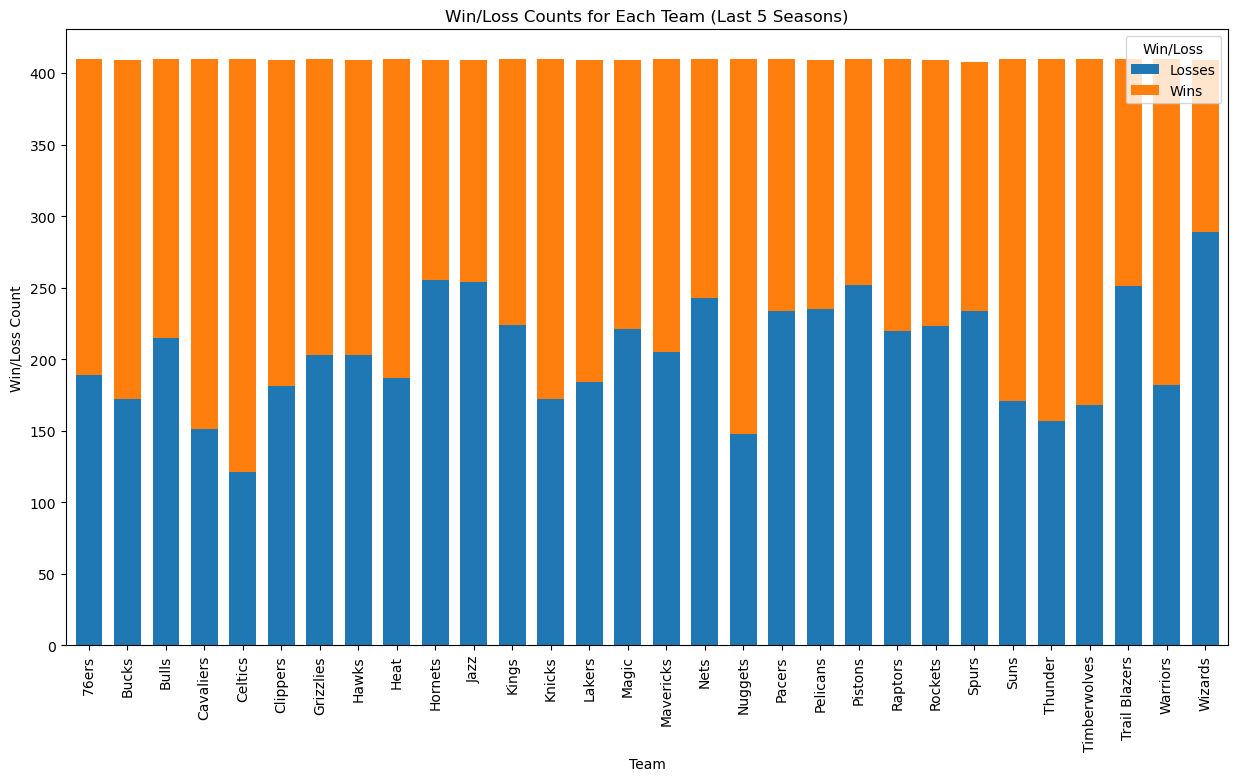

In [12]:
#Visualize the difference in shooting, rebounds, turnovers, and assists between winning and losing 
#Show wins vs losses in a count plot

win_loss_counts = filtered_teams.groupby(["teamName", "win"]).size().unstack(fill_value=0)
ax = win_loss_counts.plot(kind="bar", stacked=True, figsize=(15, 8), width=0.70)

ax.set_title("Win/Loss Counts for Each Team (Last 5 Seasons)")
ax.set_xlabel("Team")
ax.set_ylabel("Win/Loss Count")
ax.legend(title="Win/Loss", labels=["Losses", "Wins"])

In [13]:
#Display stats for wins vs losses in the eastern conf. 
eastern_mask = team_last_5_seasons["teamName"].isin(eastern_teams)
eastern_wins = team_last_5_seasons.loc[eastern_mask & team_last_5_seasons["win"].eq(1)]
eastern_losses = team_last_5_seasons.loc[eastern_mask & team_last_5_seasons["win"].eq(0)]

eastern_shooting_stats = pd.DataFrame({
    "Wins": eastern_wins[stats].mean(),
    "Losses": eastern_losses[stats].mean()
})
print(eastern_shooting_stats)

                              Wins     Losses
fieldGoalsPercentage      0.494176   0.444381
threePointersPercentage   0.387846   0.329963
freeThrowsPercentage      0.794358   0.773667
reboundsTotal            45.686528  41.604673
turnovers                13.055942  13.998720
assists                  27.487918  24.237516


In [14]:
#Display shooting percentage for wins vs losses in the western conf. 
western_mask = team_last_5_seasons["teamName"].isin(western_teams)
western_wins = team_last_5_seasons.loc[western_mask & team_last_5_seasons["win"].eq(1)]
western_losses = team_last_5_seasons.loc[western_mask & team_last_5_seasons["win"].eq(0)]

western_shooting_stats = pd.DataFrame({
    "Wins": western_wins[stats].mean(),
    "Losses": western_losses[stats].mean()
})
print(western_shooting_stats)

                              Wins     Losses
fieldGoalsPercentage      0.497732   0.446791
threePointersPercentage   0.388193   0.330905
freeThrowsPercentage      0.788021   0.765566
reboundsTotal            46.000640  42.166887
turnovers                13.516491  14.442053
assists                  27.781300  24.426490


**RQ1 interpretation:** Winning teams do better on every measure. They shoot about 5 points better on field goals (49.3% vs. 44.3% in the East, 49.6% vs. 44.6% in the West) and 5-6 points better from three (38.6% vs. 32.9% East, 38.7% vs. 33.0% West), grab about 4 more rebounds, turn the ball over about 1 fewer time, and record about 3 more assists. Free throw percentage differs by only about 2 points. The pattern is the same in both conferences, so conference does not seem to change what winning looks like. These are associations in game averages, not proof that any one stat causes a win: a team that is winning also gets better shots, and a team that shoots well is more likely to win.

In [15]:
#Summary statistics for the stats and teamScore
team_last_5_seasons[stats + ["teamScore"]].describe()

,fieldGoalsPercentage,threePointersPercentage,freeThrowsPercentage,reboundsTotal,turnovers,assists,teamScore
count,12288.000000,12288.000000,12288.000000,12288.000000,12288.000000,12288.000000,12288.000000
mean,0.470775,0.359224,0.780411,43.863607,13.753337,25.983724,113.792887
std,0.055005,0.082199,0.100155,6.707454,3.894049,5.185222,12.728580
min,0.277000,0.069000,0.000000,20.000000,2.000000,8.000000,66.000000
25%,0.433000,0.303750,0.714000,39.000000,11.000000,22.000000,105.000000
50%,0.470000,0.357000,0.786000,44.000000,14.000000,26.000000,113.000000
75%,0.506000,0.414000,0.850000,48.000000,16.000000,29.000000,122.000000
max,0.689000,0.680000,1.000000,74.000000,31.000000,50.000000,176.000000


**Spread of the stats:** Team scores average about 114 points with a standard deviation of about 13, so most games fall between roughly 101 and 127 points. Field goal percentage averages 0.47 (std 0.06), three point percentage 0.36 (std 0.08) and free throw percentage 0.78 (std 0.10). Rebounds average about 44 (std 6.7), turnovers about 14 (std 3.9) and assists about 26 (std 5.2). The standard deviations are large relative to the winner-loser gaps, which is why individual games overlap a lot even though the averages differ clearly.

In [16]:
#Question 2: How does playing at home vs away relate to winning and scoring?
home_away = team_last_5_seasons.assign(location=team_last_5_seasons["home"].map({1: "Home", 0: "Away"}))
print(home_away.groupby("location").agg(
    win_rate=("win", "mean"),
    avg_teamScore=("teamScore", "mean"),
    games=("win", "size")
).round(3))

          win_rate  avg_teamScore  games
location                                
Away         0.447        112.822   6144
Home         0.553        114.764   6144


**RQ2 result:** Home teams win about 55.3% of their games and away teams about 44.7%, and home teams score about 2 more points on average (114.8 vs. 112.8). Home court is associated with a modest but consistent edge. It is far smaller than the gaps in shooting between winners and losers, and the data cannot say why (crowd, travel, rest, or referees).

In [17]:
#Categorical analysis
print(team_last_5_seasons["win"].value_counts(normalize=True))
print(team_last_5_seasons["gameType"].value_counts())

win
1.0    0.5
0.0    0.5
Name: proportion, dtype: float64
gameType
Regular Season    12288
Name: count, dtype: int64


**Categorical analysis:** Wins and losses are split 50/50, which is expected: every game produces exactly one winner and one loser, so `win` carries no information on its own. `gameType` is "Regular Season" for every row, which confirms the filter in Part B worked.

In [18]:
#Correlation matrix of the stats and teamScore (feeds the heatmap in Part D)
#RQ3: which stat is most strongly related to teamScore?
corr = team_last_5_seasons[stats + ["teamScore"]].corr()
print(corr.round(2))
print(corr["teamScore"].drop("teamScore").sort_values(ascending=False).round(2))

                         fieldGoalsPercentage  threePointersPercentage  \
fieldGoalsPercentage                     1.00                     0.56   
threePointersPercentage                  0.56                     1.00   
freeThrowsPercentage                     0.02                     0.02   
reboundsTotal                           -0.18                    -0.13   
turnovers                                0.01                    -0.00   
assists                                  0.56                     0.43   
teamScore                                0.73                     0.56   

                         freeThrowsPercentage  reboundsTotal  turnovers  \
fieldGoalsPercentage                     0.02          -0.18       0.01   
threePointersPercentage                  0.02          -0.13      -0.00   
freeThrowsPercentage                     1.00          -0.04      -0.01   
reboundsTotal                           -0.04           1.00       0.11   
turnovers                       

**RQ3 (team-level): Which team stat is most strongly related to how many points a team scores?** Field goal percentage has the strongest relationship with `teamScore` (r of about 0.73), followed by assists (0.62) and three point percentage (0.56). Free throw percentage (0.15) and rebounds (0.11) are weak, and turnovers are slightly negative (-0.17). These are correlations, so they describe association only.

## Part D - Visualizations
The stacked bar chart above shows each team's wins and losses over the last 5 seasons. The charts below show the shooting gap between winners and losers, the scoring distribution, how the stats relate to each other, and the home vs. away win rate.

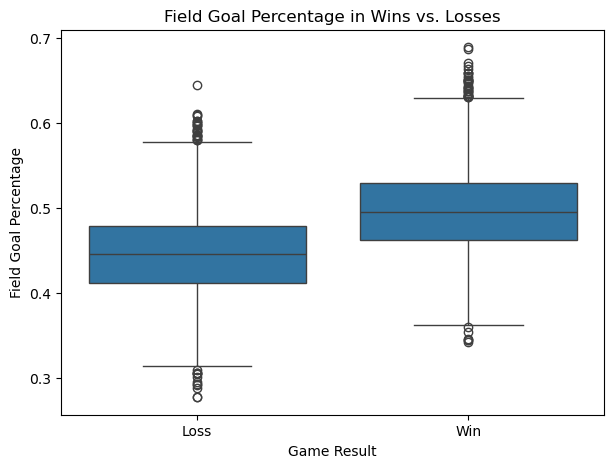

In [19]:
#Boxplot: field goal percentage for wins vs losses
plt.figure(figsize=(7, 5))
sns.boxplot(
    x=team_last_5_seasons["win"].map({1: "Win", 0: "Loss"}),
    y=team_last_5_seasons["fieldGoalsPercentage"],
    order=["Loss", "Win"]
)
plt.title("Field Goal Percentage in Wins vs. Losses")
plt.xlabel("Game Result")
plt.ylabel("Field Goal Percentage")
plt.show()

**Boxplot:** The whole distribution of field goal percentage shifts up for winners, not only the average. The median for winners (about 0.50) is close to the 75th percentile for losers, and the two boxes overlap only a little, but there are still some losses with high shooting and wins with low shooting.

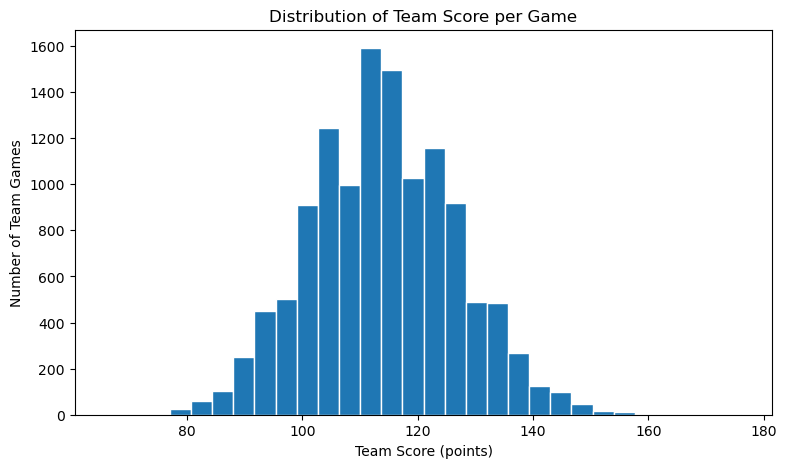

In [26]:
#Histogram of team scores
plt.figure(figsize=(9, 5))
plt.hist(team_last_5_seasons["teamScore"], bins=30, edgecolor="white")
plt.title("Distribution of Team Score per Game")
plt.xlabel("Team Score (points)")
plt.ylabel("Number of Team Games")
plt.show()

**Histogram:** Team scores are roughly bell-shaped and centered near 115 points, with most games between about 105 and 125. The tails run from the mid-70s to around 150+.

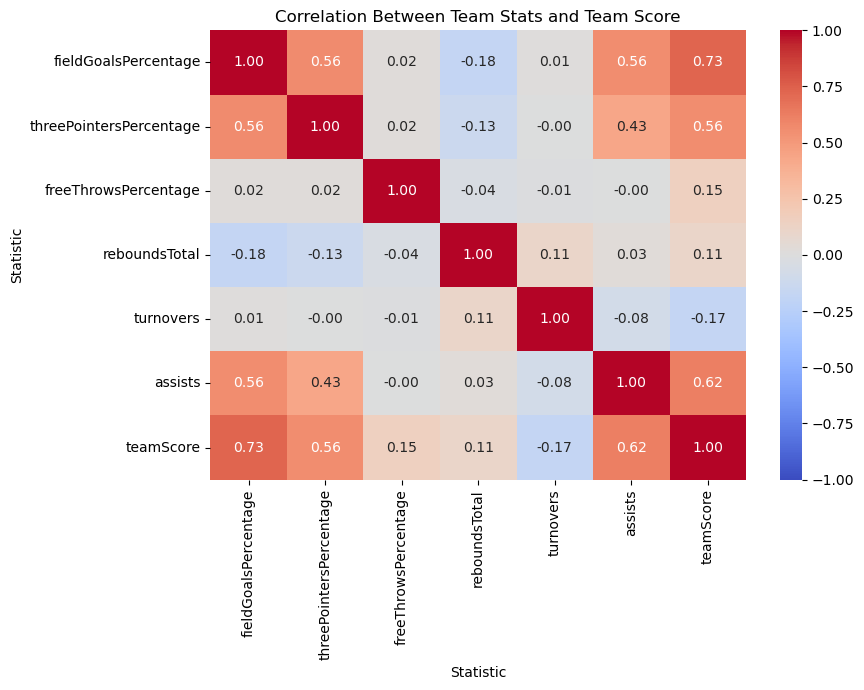

In [21]:
#Heatmap of the correlation matrix
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Team Stats and Team Score")
plt.xlabel("Statistic")
plt.ylabel("Statistic")
plt.tight_layout()
plt.show()

**Heatmap:** Field goal percentage, assists, and three point percentage are the strongest correlates of `teamScore` (dark red). Field goal percentage, assists and three point percentage are also correlated with each other (0.4 to 0.6), which makes sense because assisted threes and layups are efficient shots. Free throw percentage, rebounds and turnovers are close to zero and show little linear relationship with the other stats.

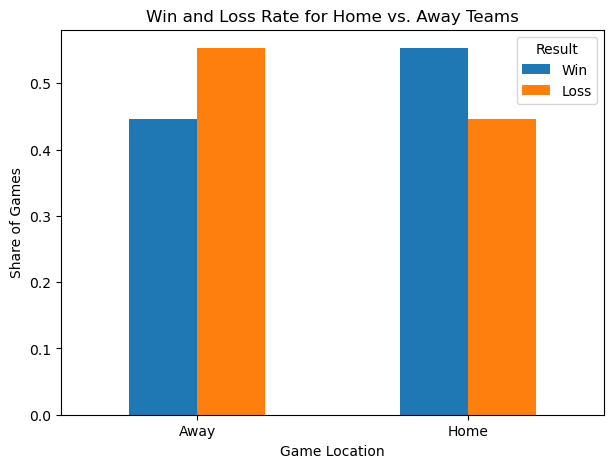

In [22]:
#Grouped bar chart: home vs away win rate (RQ2)
rate = pd.crosstab(
    team_last_5_seasons["home"].map({1: "Home", 0: "Away"}),
    team_last_5_seasons["win"].map({1: "Win", 0: "Loss"}),
    normalize="index"
)[["Win", "Loss"]]
ax = rate.plot(kind="bar", figsize=(7, 5), rot=0)
ax.set_title("Win and Loss Rate for Home vs. Away Teams")
ax.set_xlabel("Game Location")
ax.set_ylabel("Share of Games")
ax.legend(title="Result")
plt.show()

**Grouped bar chart:** Home teams win about 55% of their games and away teams about 45%, a gap of roughly 10 percentage points. The two bars in each group are mirror images because every game has exactly one winner and one loser.

## Part E - Findings and Limitations

**Findings**
1. **Winners shoot better, rebound more, and share the ball more (RQ1).** Across the last 5 regular seasons winners average about 50% from the field vs. 45% for losers, 39% vs. 33% from three, 45.9 vs. 41.9 rebounds, 13.3 vs. 14.2 turnovers, and 27.6 vs. 24.3 assists. The gaps are almost identical in the Eastern and Western conferences. Free throw percentage barely differs (about 2 points).
2. **Home court is worth a few points and about 10 percentage points of win rate (RQ2).** Home teams won 55.3% of games vs. 44.7% for away teams and scored about 2 more points on average (114.8 vs. 112.8).
3. **Field goal percentage is the stat most tied to scoring (RQ3).** Its correlation with `teamScore` is about 0.73, ahead of assists (0.62) and three point percentage (0.56). Rebounds (0.11) and turnovers (-0.17) are only weakly related to how many points a team scores. Typical team scoring is about 114 points per game with a standard deviation of about 13.

**Limitations**
1. **Game-level team averages hide player effects.** Each row is one team in one game, so the data cannot say whether a hot shooting night came from one star or the whole roster, or how injuries and minutes played changed the result.
2. **The data covers only 5 seasons** (2021-22 to the start of 2026-27), and the 2026-27 season only has a handful of games. Playing styles change, so the patterns may not hold for earlier eras. Several detail columns (quarter scores, bench points) are missing for 2021-22, so I could not use them.
3. **The results are correlational, not causal.** Winning teams shoot better, but shooting well is partly the result of building a big lead against a team that gave up, and the box score cannot separate the two. I also did not control for opponent strength.